In [ ]:
# Creating a figures dataset to store all generated figures.
from pathlib import Path

FIG_DIR = Path("figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Figure 1C

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
total_counts_public = pd.read_csv("fig_1C_total_protein_counts_per_celltype_per_sample.csv")

In [3]:
# Average across samples in each dataset to get average total counts for each dataset.
dataset_level = (
    total_counts_public
    .groupby(
        ["dataset_identifier", "cell_type"],
        as_index=False, observed=True
    )["mean_protein_counts_per_sample"]
    .mean()
    .rename(columns={
        "mean_protein_counts_per_sample": "mean_total_protein_counts"
    })
)

In [4]:
# Scale mean total protein counts by the dataset median total protein counts.
dataset_medians = dataset_level.groupby("dataset_identifier", observed=True)["mean_total_protein_counts"].median()
dataset_level["scaled_mean_total_protein_counts"] = dataset_level["mean_total_protein_counts"]/dataset_level["dataset_identifier"].map(dataset_medians)

In [5]:
# Sort cell types by total protein counts.
order = dataset_level.groupby("cell_type", observed=True)["scaled_mean_total_protein_counts"].median().sort_values(ascending=False).index

In [6]:
cell_types_palette = {'T':"#B5DEAD", 'NK': "#CBC0AD", 'B': "#6EA4BF", 'Plasma': "#3b3b3b", 'DC': "#B2ABF2" , 'Mo/Mac': "#A833B9", 'RBC': "#FF0000", "Gran": "#FFD580"}

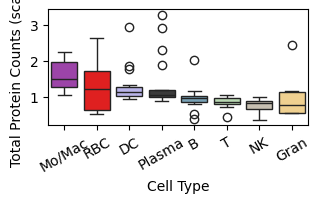

In [7]:
fig,ax = plt.subplots(figsize=(3.35, 1.5))
sns.boxplot(dataset_level, x="cell_type", y="scaled_mean_total_protein_counts", hue="cell_type", legend=False, palette=cell_types_palette, order=order, ax=ax)
plt.xticks(rotation=30)
plt.ylabel("Total Protein Counts (scaled)")
plt.xlabel("Cell Type")
plt.savefig("figures/Figure_1C.svg", dpi=600)

# Figure 2

In [8]:
import scanpy as sc
import numpy as np
from muon import prot as pt
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter

import utils

/home/marchena/miniconda3/envs/python_3.14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [9]:
rna = sc.read_h5ad("scmultisim_rna_data.h5ad")
protein = sc.read_h5ad("scmultisim_protein_data.h5ad")

In [10]:
rcparams = {'font.size': 7,
    'axes.titlesize': 7,
    'axes.labelsize': 7,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'legend.fontsize': 7,
    'figure.titlesize': 7,
    'text.usetex': False, # Times with Latex rendering gives problems with axes in Matplotlib.
    'font.family': 'sans-serif',
    'font.sans-serif': ['DejaVu Sans'],
    'mathtext.fontset': 'dejavusans', 
    'mathtext.rm': 'DejaVu Sans',
    'mathtext.it': 'DejaVu Sans:italic',
    'mathtext.bf': 'DejaVu Sans:bold',
           }
plt.rcParams.update(rcparams)

In [11]:
cell_type_scmultisim_palette = {"1": '#A28497', "2": '#495F41', "3": '#86BBD8'}
dataset_full_names = { "RNA": "RNA", 'protein_raw': "Raw protein", 'protein_uncorrected': "Uncorrected", "library_normalization": "Library normalization", "CLR_normalization": "CLR normalization", "CLR_normalization_stoeckius": "CLR normalization Stoeckius", "CLR_normalization_across_ab": "CLR normalization across proteins" ,"KNN_protein_neighbors": "KNN normalization, protein", "KNN_RNA_neighbors": "KNN normalization, RNA"}

In [12]:
protein.layers["raw"] = protein.X.toarray().copy()
rna.obs["Cell type"] = [str(pop) for pop in rna.obs["pop"]]
protein.obs["Cell type"] = [str(pop) for pop in protein.obs["pop"]]
protein.uns["Cell type_colors"] = list(cell_type_scmultisim_palette.values())

In [13]:
# Generating true size factors
variance = 0.5
np.random.seed(42)
true_size_factors = np.exp(np.random.normal(0, variance, protein.n_obs))

In [14]:
# Multiplying protein data by size factors
protein.X = (true_size_factors * (protein.layers["raw"].T)).T
protein.obs["true_size_factor"] = true_size_factors

In [15]:
# Figure 2A
utils.sum_total_counts(protein)

fig, ax = plt.subplots(figsize=(2.12, 1.60), dpi=300, constrained_layout=True)
sc.pl.violin(
    protein,
    keys="total_counts",
    groupby="Cell type",
    show=False,
    hue="Cell type",
    palette=cell_type_scmultisim_palette,
    log=True,
    dodge=False,      # <- keeps dots and violins centered on each category
    ax=ax,
)
plt.ylabel("Total protein counts")
plt.xlabel("Cell type")
plt.savefig("figures/Figure_2A.svg")
plt.close("all")

NO NORMALIZE AND USE PREPROCESS RNA TRUE OR EVEN REMOVE PREPROCESS RNA

In [16]:
# sc.pp.normalize_total(rna)
# sc.pp.log1p(rna)
# utils.pca_neighbors_umap(rna)

In [17]:
# Apply normalization methods
protein.layers["clr_across_cells"] = pt.pp.clr(protein, axis=1, inplace=False).X
protein.layers["clr_across_cells_stoeckius"] = pt.pp.clr(protein, axis=1, inplace=False, flavor="stoeckius").X
protein.layers["clr_across_ab"] = pt.pp.clr(protein, axis=0, inplace=False).X

In [18]:
normalized_data = utils.apply_normalization_methods(protein_data=protein, rna_data=rna, use_PCA_for_protein=True, log_transform=True)

Starting sample
PCA_neighbors_UMAP
Storing Anndata objects
Uncorrected protein
protein library-size normalized
protein CLR normalized
protein CLR normalized Stoeckius
protein CLR normalized across proteins
KNN normalization with RNA neighbors
Calculating KNN graph from RNA data


/groups/nils/members/javier/KNN_normalization_paper_code/utils.py:309: UserWarning: The protein data is not integer-valued. KNN normalization expects raw counts.
  mudata_knn_normalized = knn.knn_normalize(mudata, calculate_neighbors_from="rna",


Running KNN normalization
Iteration 1
Iteration 2
Change wrt previous iteration: 2.892332373869726
Iteration 3
Change wrt previous iteration: 0.1953317644874376
Iteration 4
Change wrt previous iteration: 0.0339336335839765
Iteration 5
Change wrt previous iteration: 0.004593276400019497
Iteration 6
Change wrt previous iteration: 0.001021192270796334
Iteration 7
Change wrt previous iteration: 0.0002651268734046308
KNN normalization with protein neighbors
Calculating KNN graph from protein data
Running KNN normalization
Iteration 1
Iteration 2
Change wrt previous iteration: 2.579794759743154
Iteration 3
Change wrt previous iteration: 0.17720229928788678
Iteration 4
Change wrt previous iteration: 0.05463800886245729
Iteration 5
Change wrt previous iteration: 0.023751305893602637
Iteration 6
Change wrt previous iteration: 0.010802982442726816
Iteration 7
Change wrt previous iteration: 0.005444537876780231
Iteration 8
Change wrt previous iteration: 0.002802790962028734
Iteration 9
Change wrt

/groups/nils/members/javier/KNN_normalization_paper_code/utils.py:324: UserWarning: The protein data is not integer-valued. KNN normalization expects raw counts.
  protein_knn_normalized_cosine = knn.knn_normalize(protein_data, calculate_neighbors_from="prot", log_transform=log_transform,


In [19]:
for dataset in normalized_data.keys():
    sc.tl.pca(normalized_data[dataset], random_state=43)
    sc.tl.umap(normalized_data[dataset], random_state=43)

In [20]:
# Figure 2B-C
dotsize=25
figsize=(2.12, 1.60)
    
# Plotting total counts in the UMAPs.
for dataset in normalized_data.keys():
    fig,ax = plt.subplots(figsize=figsize, dpi=600)
    sc.pl.pca(normalized_data[dataset], color="log_total_counts", show=False, legend_loc=None, ax=ax,
             title=dataset_full_names[dataset], size=dotsize, frameon=False)

    cbar_ax = [a for a in fig.axes if a is not ax][0]
    cbar_ax.set_ylabel(r"Log$_{10}$ total protein counts", rotation=270, labelpad=8, va="center")
    ticks = np.linspace(cbar_ax.get_ylim()[0], cbar_ax.get_ylim()[1], 3)
    cbar_ax.set_yticks(ticks)
    cbar_ax.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))
    for coll in ax.collections:
        coll.set_rasterized(True)
    plt.savefig(f"figures/Figure_2B_PCA_{dataset}_log_total_counts.svg", bbox_inches="tight")
    plt.close("all")

    fig,ax = plt.subplots(figsize=figsize, dpi=600)
    sc.pl.pca(normalized_data[dataset], color=["Cell type"], annotate_var_explained=True,
     title = [dataset_full_names[dataset]], show=False, legend_loc="on data", ax=ax, size=dotsize)   
    ax.set_xlabel(ax.get_xlabel().split('(')[0] +
    f"({int(float(ax.get_xlabel().split('(')[1].split('%')[0]))}%)")
    ax.set_ylabel(ax.get_ylabel().split('(')[0] +
    f"({int(float(ax.get_ylabel().split('(')[1].split('%')[0]))}%)")
    for coll in ax.collections:
        coll.set_rasterized(True)
    plt.savefig(f"figures/Figure_2C_PCA_{dataset}_cell_type.svg")
    plt.close("all")

In [21]:
# Figure 2D
for normalization in normalized_data.keys():
    if normalization not in ("RNA", "protein_raw", "protein_uncorrected", "CLR_normalization_across_ab"): # RNA, protein_raw and protein_uncorrected are not normalized, so we cannot compare their calculated size factors.
        
        if "KNN" in normalization:
            estimated_factor = "inverse_total_size_factor" 
            yticks = [0, 1, 2, 3]
        elif "CLR" in normalization:
            estimated_factor = "geom_mean" 
            yticks = [0, 200, 400, 600]
        elif "library_normalization" in normalization:
            estimated_factor = "librarynorm_size_factors"
            yticks = [0, 2, 4, 6]
        else:
            print("What kind of normalization are you using?")
            
        print(normalization)

        utils.compare_size_factors(anndata=normalized_data[normalization],estimated_size_factor=estimated_factor,
                                          saveplotname=f"figures/size_factor_comparison_{normalization}.svg", plot_title = dataset_full_names[normalization],
                                      palette=cell_type_scmultisim_palette, xticks = [0, 1, 2, 3], yticks = yticks)
        
        plt.close("all")

library_normalization
CLR_normalization
CLR_normalization_stoeckius
KNN_RNA_neighbors
KNN_protein_neighbors


# Figure 3

In [22]:
import scanpy as sc
import muon as mu
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter

import utils # From the utils.py file.

In [23]:
rna = sc.read_h5ad("Immune_colon_rna_data.h5ad")
protein = sc.read_h5ad("Immune_colon_protein_data.h5ad")

In [24]:
remove_cell_types = ['NK', 'Mono', 'Mono-Macro', 'Mast', 'Macro', 'DC', "Treg", "Myeloid", "pDC"]
protein = protein[~protein.obs["RNA-based_cell_type_coarse"].isin(remove_cell_types)].copy()
rna = rna[~rna.obs["RNA-based_cell_type_coarse"].isin(remove_cell_types)].copy()

In [25]:
samples = ["p026t", "p042t", "p046t"] # Samples with more than 400 cells.
protein = protein[protein.obs["sample"].isin(samples)].copy()
rna = rna[rna.obs["sample"].isin(samples)].copy()

In [26]:
t_cell_markers = ['CD8a', 'CD4', 'CD45RO', 'CD28', 'CD5', 'CD3']
protein = protein[:, t_cell_markers].copy()

In [27]:
# Remove the 0.5% cells with highest total counts.
utils.sum_total_counts(protein)
protein, rna = utils.remove_very_high_total_counts_by_sample(protein, rna, "sample", 99.5)

In [28]:
protein.layers["clr_across_cells_stoeckius"] = mu.prot.pp.clr(protein, axis=1, flavor="stoeckius", inplace=False).X
protein.layers["clr_across_cells"] = mu.prot.pp.clr(protein, axis=1, flavor="seurat", inplace=False).X
protein.layers["clr_across_ab"] = mu.prot.pp.clr(protein, axis=0, flavor="seurat", inplace=False).X

In [29]:
sample_list = rna.obs["sample"].unique()
data_samples = utils.normalize_per_sample(protein_data=protein, rna_data=rna,
                              sample_list=sample_list, sample_column_name="sample", use_PCA_for_protein=False,
                                             log_transform=True, scale_protein=True, verbose=False)

p026t


/home/marchena/miniconda3/envs/python_3.14/lib/python3.14/site-packages/mudata/_core/mudata.py:988: UserWarning: var_names are not unique. To make them unique, call `.var_names_make_unique`.
  self._update_attr("var", axis=1, join_common=join_common)
/home/marchena/miniconda3/envs/python_3.14/lib/python3.14/site-packages/mudata/_core/mudata.py:988: UserWarning: var_names are not unique. To make them unique, call `.var_names_make_unique`.
  self._update_attr("var", axis=1, join_common=join_common)


p042t


/home/marchena/miniconda3/envs/python_3.14/lib/python3.14/site-packages/mudata/_core/mudata.py:988: UserWarning: var_names are not unique. To make them unique, call `.var_names_make_unique`.
  self._update_attr("var", axis=1, join_common=join_common)
/home/marchena/miniconda3/envs/python_3.14/lib/python3.14/site-packages/mudata/_core/mudata.py:988: UserWarning: var_names are not unique. To make them unique, call `.var_names_make_unique`.
  self._update_attr("var", axis=1, join_common=join_common)


p046t


/home/marchena/miniconda3/envs/python_3.14/lib/python3.14/site-packages/mudata/_core/mudata.py:988: UserWarning: var_names are not unique. To make them unique, call `.var_names_make_unique`.
  self._update_attr("var", axis=1, join_common=join_common)
/home/marchena/miniconda3/envs/python_3.14/lib/python3.14/site-packages/mudata/_core/mudata.py:988: UserWarning: var_names are not unique. To make them unique, call `.var_names_make_unique`.
  self._update_attr("var", axis=1, join_common=join_common)


In [30]:
rcparams = {'font.size': 7,
    'axes.titlesize': 7,
    'axes.labelsize': 7,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'legend.fontsize': 7,
    'figure.titlesize': 7,
    'text.usetex': False, # Times with Latex rendering gives problems with axes in Matplotlib.
    'font.family': 'sans-serif',
    'font.sans-serif': ['DejaVu Sans'],
    'mathtext.fontset': 'dejavusans', 
    'mathtext.rm': 'DejaVu Sans',
    'mathtext.it': 'DejaVu Sans:italic',
    'mathtext.bf': 'DejaVu Sans:bold',
           }
plt.rcParams.update(rcparams)

In [31]:
for dataset in data_samples.keys():
    sc.tl.pca(data_samples[dataset], random_state=43)
    sc.tl.umap(data_samples[dataset], random_state=43)

In [32]:
dotsize=20 # dot size of each cell in the PCA/UMAP
figsize=(1.9, 1.60)
figsize_pca_celltype = (1.72, 1.6)
cell_type_annotation = "RNA-based_cell_type_coarse"
cell_types_palette = {'CD4 T': "#F75C03", 'CD8 T': "#157F1F", 'B': "#6EA4BF", 'Plasma': "#1A181B"}
    
for dataset in data_samples.keys():
    if ("RNA" not in dataset) or ("KNN" in dataset):
        # Figure 3A: PCA with cell types
        fig,ax = plt.subplots(figsize=figsize_pca_celltype, dpi=300)
        sc.pl.pca(data_samples[dataset], color=[cell_type_annotation], annotate_var_explained=True,
         show=False, ax=ax, size=dotsize)
        ax.set_xlabel(ax.get_xlabel().split('(')[0] +
        f"({int(float(ax.get_xlabel().split('(')[1].split('%')[0]))}%)")
        ax.set_ylabel(ax.get_ylabel().split('(')[0] +
        f"({int(float(ax.get_ylabel().split('(')[1].split('%')[0]))}%)")
        plt.savefig(f"figures/Figure_3A_PCA_{dataset}_cell_type.svg")
        plt.close("all")

        # Figure 3B: PCA with log10 total counts
        fig,ax = plt.subplots(figsize=figsize, dpi=300)
        sc.pl.pca(data_samples[dataset], color="log_total_counts", show=False, legend_loc=None, ax=ax,
                 size=dotsize, frameon=False)
        cbar_ax = [a for a in fig.axes if a is not ax][0]
        cbar_ax.set_ylabel(r"Log$_{10}$ total protein counts", rotation=270, labelpad=8, va="center")
        ticks = np.linspace(cbar_ax.get_ylim()[0], cbar_ax.get_ylim()[1], 3)
        cbar_ax.set_yticks(ticks)
        cbar_ax.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))
        plt.savefig(f"figures/Figure_3B_PCA_{dataset}_log_total_counts.svg")
        plt.close("all")

        # Figure 3C: Heatmap
        sample_data = data_samples[dataset].copy()
        df = pd.DataFrame(sample_data.X, columns=sample_data.var_names, index=sample_data.obs_names)
        df["cell_type"] = sample_data.obs["RNA-based_cell_type_coarse"]
        df = df.groupby("cell_type", observed=True).mean()
        ticks = [-1, 0, 1]

        fig, ax = plt.subplots(figsize=(2.16, 1.5), dpi=300)
        sns.heatmap(df, cmap="RdBu_r", center=0, ax=ax, cbar_kws={"ticks": ticks}, vmin=-1, vmax=1)
        plt.ylabel("")

        ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='center')
        ax.set_yticklabels(ax.get_yticklabels(), rotation=0, ha='right', fontweight="bold")

        for tick in ax.get_yticklabels():
            cell_type = tick.get_text()
            color = cell_types_palette.get(cell_type, "black")
            tick.set_color(color) # Color each y-axis tick label by cell type

        plt.savefig(f"figures/Figure_3C_heatmap_{dataset}_{cell_type_annotation}.svg", dpi=300, bbox_inches="tight")
        plt.close("all")

In [33]:
# Figure 3D: Bounded max ARI.
methods_palette = {"Uncorrected": "#FFB49A", "Library normalization": "#008080", "CLR normalization": "#7b7554", "KNN normalization, protein": "#51CB20", "KNN normalization, RNA": "#A11692", "CLR normalization Stoeckius": "#FFD166", "CLR normalization across ab": "#1B5299"}
profi = False
subsample_silhouette = False
use_pca_silhouette = True
sample_word_number = 1
resolutions = np.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2., 2.1, 2.2, 2.3, 2.4, 2.5, 2.6, 2.7, 2.8, 2.9, 3, 3.1, 3.2, 3.3, 3.4, 3.5, 3.6, 3.7, 3.8, 3.9, 4])
for resolution in resolutions:
    for dataset in data_samples.keys():
        sc.tl.leiden(data_samples[dataset], resolution=resolution, key_added=f"leiden_{resolution}", flavor="igraph")

selected_dataset_and_methods = {'protein_uncorrected': 'Uncorrected',
 'CLR_normalization': 'CLR normalization',
 'KNN_protein_neighbors': 'KNN normalization, protein',
 'KNN_RNA_neighbors': 'KNN normalization, RNA'}

# If you want to include CLR normalization with Stoeckius flavor and inside each protein, uncomment the following lines.
# selected_dataset_and_methods = {'protein_uncorrected': 'Uncorrected',
#  'CLR_normalization': 'CLR normalization',
#  "CLR_normalization_stoeckius": "CLR normalization Stoeckius",
#  "CLR_normalization_across_ab": "CLR normalization across ab",
#  'KNN_protein_neighbors': 'KNN normalization, protein',
#  'KNN_RNA_neighbors': 'KNN normalization, RNA'}
profi=True
figsize=(0.8, 3)
utils.calculate_ari_bounded_max(data_samples, ["RNA-based_cell_type_coarse"], save_directory=f"figures", samples_to_average=samples, sample_word_number=sample_word_number, resolutions=resolutions, selected_dataset_and_methods=selected_dataset_and_methods, methods_palette=methods_palette, profi=profi, figsize=figsize, rcparams=rcparams)

# Figure 4

# Supplementary Figure 1B

In [34]:
from knn_normalization import knn_normalize
import matplotlib as mpl
import seaborn as sns

In [35]:
protein = sc.read_h5ad("Immune_colon_protein_data.h5ad")
sample_protein = protein[protein.obs["sample"] == "p042t"].copy() 

In [36]:
knn_normalize(sample_protein, calculate_neighbors_from="prot", save_size_factors=True)
size_factor_history = sample_protein.obsm["size_factor_history"]

Calculating KNN graph from protein data
Running KNN normalization
Iteration 1
Iteration 2
Change wrt previous iteration: 2.8091752090296596
Iteration 3
Change wrt previous iteration: 0.14985611534427812
Iteration 4
Change wrt previous iteration: 0.05433303705053372
Iteration 5
Change wrt previous iteration: 0.029019858284483613
Iteration 6
Change wrt previous iteration: 0.016267248006852753
Iteration 7
Change wrt previous iteration: 0.00919104640129409
Iteration 8
Change wrt previous iteration: 0.005290864952985586
Iteration 9
Change wrt previous iteration: 0.0031416011837783753
Iteration 10
Change wrt previous iteration: 0.0018869578050035862
Iteration 11
Change wrt previous iteration: 0.001146922361296543
Iteration 12
Change wrt previous iteration: 0.0007060264164897578
Iteration 13
Change wrt previous iteration: 0.0004436637765398155


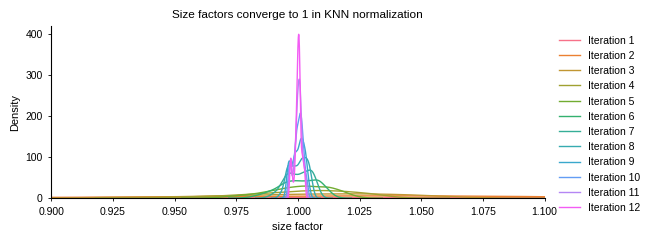

In [37]:
# same font sizes / rc as make_supp_figure.py
FS_TITLE, FS_LABEL, FS_TICK, FS_LEGEND = 8.5, 8, 7.5, 7.5
mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Liberation Sans", "DejaVu Sans"],
    "svg.fonttype": "none",
})

# panel B geometry: width of panel A (17.17 cm), height 2.6 in
w_in, h_in = 17.17 / 2.54, 2.6
fig = plt.figure(figsize=(w_in, h_in))
ax = fig.add_axes([0.08, 0.50 / h_in, 0.73, (h_in - 0.50 - 0.38) / h_in])

colors = sns.color_palette("husl", size_factor_history.shape[1])
for i in range(12):
    sns.kdeplot(size_factor_history.T[i, :], color=colors[i], label=f"Iteration {i+1}", ax=ax, lw=1.0)

ax.legend(fontsize=FS_LEGEND, frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax.set_title("Size factors converge to 1 in KNN normalization", fontsize=FS_TITLE)
ax.set_xlabel("size factor", fontsize=FS_LABEL)
ax.set_ylabel("Density", fontsize=FS_LABEL)
ax.set_xlim([0.9, 1.1])
ax.tick_params(labelsize=FS_TICK, length=2.5, width=0.6)
sns.despine(ax=ax)

fig.savefig("figures/Supplementary_Figure_1B_density_plot_size_factors_iterations.svg", dpi=500)
fig.savefig("figures/Supplementary_Figure_1B_density_plot_size_factors_iterations.png", dpi=500)


# Supplementary Figure 2

In [38]:
## Code with R kernel to download the Haoetal data and convert it to h5ad format.
# wget https://atlas.fredhutch.org/data/nygc/multimodal/pbmc_multimodal.h5seurat
# library(Seurat)
# library(SeuratData)
# library(SeuratDisk)
# hao = LoadH5Seurat("pbmc_multimodal.h5seurat")
# adts = hao[["ADT"]]
# adts_seurat = CreateSeuratObject(adts)
# raw_adts = GetAssayData(adts_seurat, slot="counts")
# raw_adts = CreateSeuratObject(raw_adts)
# SaveH5Seurat(raw_adts, filename = "Haoetal_protein.h5Seurat")
# Convert("Haoetal_protein.h5Seurat", dest = "h5ad")
# Convert("pbmc_multimodal.h5seurat", dest = "Haoetal_rna.h5ad")

In [39]:
import scanpy as sc
import muon as mu
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter

import utils  # From the utils.py file.

In [40]:
rna = sc.read_h5ad("Haoetal_rna.h5ad")
protein = sc.read_h5ad("Haoetal_protein.h5ad")
cell_type_annotation = "celltype.l1"
sample_column_name = "donor"
sample_word_number = 1

In [41]:
del rna.uns # We remove the neighbors and distances in the AnnData object because otherwise that gives errors when calculating new neighbors.
del rna.obsp

In [42]:
preserve_cell_types = ['NK', 'other T', 'CD4 T']
protein = protein[protein.obs[cell_type_annotation].isin(preserve_cell_types)].copy()
rna = rna[rna.obs[cell_type_annotation].isin(preserve_cell_types)].copy()

In [43]:
cell_types_palette = {'other T':"#B5DEAD", 'CD4 T': "#F75C03", 'NK': "#B2ABF2"}
methods_palette = {"Uncorrected": "#FFB49A", "Library normalization": "#008080", "CLR normalization": "#7b7554", "KNN normalization, protein": "#51CB20", "KNN normalization, RNA": "#A11692", "CLR normalization Stoeckius": "#FFD166", "CLR normalization across ab": "#1B5299"}
protein.uns[f"{cell_type_annotation}_colors"] = [cell_types_palette[cell_type] for cell_type in protein.obs[cell_type_annotation].cat.categories if cell_type in cell_types_palette]
rna.uns[f"{cell_type_annotation}_colors"] = [cell_types_palette[cell_type] for cell_type in rna.obs[cell_type_annotation].cat.categories if cell_type in cell_types_palette]

In [44]:
markers = ["CD127", "CD3-1", "CD3-2", "CD28", "CD27", "CD52", "CD4-1"]
protein = protein[:, markers].copy()

In [45]:
utils.sum_total_counts(protein)
protein, rna = utils.remove_very_high_total_counts_by_sample(protein, rna, sample_column_name, 99)

In [46]:
protein.layers["clr_across_cells_stoeckius"] = mu.prot.pp.clr(protein, axis=1, flavor="stoeckius", inplace=False).X
protein.layers["clr_across_cells"] = mu.prot.pp.clr(protein, axis=1, flavor="seurat", inplace=False).X
protein.layers["clr_across_ab"] = mu.prot.pp.clr(protein, axis=0, flavor="seurat", inplace=False).X

In [47]:
sample_list = rna.obs[sample_column_name].unique()
data_samples = utils.normalize_per_sample(protein_data=protein, rna_data=rna,
                              sample_list=sample_list, sample_column_name=sample_column_name, use_PCA_for_protein=False,
                                             log_transform=True, n_neighbors=None, verbose=False)

P1


/home/marchena/miniconda3/envs/python_3.14/lib/python3.14/site-packages/mudata/_core/mudata.py:988: UserWarning: var_names are not unique. To make them unique, call `.var_names_make_unique`.
  self._update_attr("var", axis=1, join_common=join_common)
/home/marchena/miniconda3/envs/python_3.14/lib/python3.14/site-packages/mudata/_core/mudata.py:988: UserWarning: var_names are not unique. To make them unique, call `.var_names_make_unique`.
  self._update_attr("var", axis=1, join_common=join_common)


P3


/home/marchena/miniconda3/envs/python_3.14/lib/python3.14/site-packages/mudata/_core/mudata.py:988: UserWarning: var_names are not unique. To make them unique, call `.var_names_make_unique`.
  self._update_attr("var", axis=1, join_common=join_common)
/home/marchena/miniconda3/envs/python_3.14/lib/python3.14/site-packages/mudata/_core/mudata.py:988: UserWarning: var_names are not unique. To make them unique, call `.var_names_make_unique`.
  self._update_attr("var", axis=1, join_common=join_common)


P2


/home/marchena/miniconda3/envs/python_3.14/lib/python3.14/site-packages/mudata/_core/mudata.py:988: UserWarning: var_names are not unique. To make them unique, call `.var_names_make_unique`.
  self._update_attr("var", axis=1, join_common=join_common)
/home/marchena/miniconda3/envs/python_3.14/lib/python3.14/site-packages/mudata/_core/mudata.py:988: UserWarning: var_names are not unique. To make them unique, call `.var_names_make_unique`.
  self._update_attr("var", axis=1, join_common=join_common)


... (6 outputs left out)

P7


/home/marchena/miniconda3/envs/python_3.14/lib/python3.14/site-packages/mudata/_core/mudata.py:988: UserWarning: var_names are not unique. To make them unique, call `.var_names_make_unique`.
  self._update_attr("var", axis=1, join_common=join_common)
/home/marchena/miniconda3/envs/python_3.14/lib/python3.14/site-packages/mudata/_core/mudata.py:988: UserWarning: var_names are not unique. To make them unique, call `.var_names_make_unique`.
  self._update_attr("var", axis=1, join_common=join_common)


P5


/home/marchena/miniconda3/envs/python_3.14/lib/python3.14/site-packages/mudata/_core/mudata.py:988: UserWarning: var_names are not unique. To make them unique, call `.var_names_make_unique`.
  self._update_attr("var", axis=1, join_common=join_common)
/home/marchena/miniconda3/envs/python_3.14/lib/python3.14/site-packages/mudata/_core/mudata.py:988: UserWarning: var_names are not unique. To make them unique, call `.var_names_make_unique`.
  self._update_attr("var", axis=1, join_common=join_common)


In [48]:
rcparams = {'font.size': 7,
    'axes.titlesize': 7,
    'axes.labelsize': 7,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'legend.fontsize': 7,
    'figure.titlesize': 7,
    'text.usetex': False, # Times with Latex rendering gives problems with axes in Matplotlib.
    'font.family': 'sans-serif',
    'font.sans-serif': ['DejaVu Sans'],
    'mathtext.fontset': 'dejavusans', 
    'mathtext.rm': 'DejaVu Sans',
    'mathtext.it': 'DejaVu Sans:italic',
    'mathtext.bf': 'DejaVu Sans:bold',
           }
plt.rcParams.update(rcparams)

In [49]:
for dataset in data_samples.keys():
    sc.tl.pca(data_samples[dataset], random_state=43)
    sc.tl.umap(data_samples[dataset], random_state=43)

In [50]:
dotsize=20
figsize=(1.9, 1.60)
figsize_pca_celltype = (1.72, 1.6)
    
for dataset in data_samples.keys():
    if ("RNA" not in dataset) or ("KNN" in dataset):
        # Supplementary Figure 2A, PCA by cell type.
        fig,ax = plt.subplots(figsize=figsize_pca_celltype, dpi=600)
        sc.pl.pca(data_samples[dataset], color=[cell_type_annotation], annotate_var_explained=True,
         show=False, ax=ax, size=dotsize)
        ax.set_xlabel(ax.get_xlabel().split('(')[0] +
        f"({int(float(ax.get_xlabel().split('(')[1].split('%')[0]))}%)")
        ax.set_ylabel(ax.get_ylabel().split('(')[0] +
        f"({int(float(ax.get_ylabel().split('(')[1].split('%')[0]))}%)")
        for coll in ax.collections:
            coll.set_rasterized(True)
        plt.savefig(f"figures/Supplementary_Fig_2A_PCA_{dataset}_cell_type.svg")
        plt.close("all")

        # Supplementary Figure 2B, PCA by log10 total protein counts.
        fig,ax = plt.subplots(figsize=figsize, dpi=600)
        sc.pl.pca(data_samples[dataset], color="log_total_counts", show=False, legend_loc=None, ax=ax,
                 size=dotsize, frameon=False)
        cbar_ax = [a for a in fig.axes if a is not ax][0]
        cbar_ax.set_ylabel(r"Log$_{10}$ total protein counts", rotation=270, labelpad=8, va="center")
        ticks = np.linspace(cbar_ax.get_ylim()[0], cbar_ax.get_ylim()[1], 3)
        cbar_ax.set_yticks(ticks)
        cbar_ax.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))
        for coll in ax.collections:
            coll.set_rasterized(True)
        plt.savefig(f"figures/Supplementary_Fig_2B_PCA_{dataset}_log_total_counts.svg")
        plt.close("all")
        
        # Supplementary Figure 2C, Heatmaps.
        protein_sample = data_samples[dataset].copy()
        df = pd.DataFrame(protein_sample.X, columns=protein_sample.var_names, index=protein_sample.obs_names)
        df["cell_type"] = protein_sample.obs[cell_type_annotation]
        df = df.groupby("cell_type", observed=True).mean()
        ticks = [-1, 0, 1]

        fig, ax = plt.subplots(figsize=(2.16, 1.5), dpi=600)
        sns.heatmap(df, cmap="RdBu_r", center=0, ax=ax, cbar_kws={"ticks": ticks}, vmin=-1, vmax=1)
        plt.ylabel("")

        ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='center')
        ax.set_yticklabels(ax.get_yticklabels(), rotation=0, ha='right', fontweight='bold')

        # Color each y-axis tick label by cell type
        for tick in ax.get_yticklabels():
            cell_type = tick.get_text()
            color = cell_types_palette.get(cell_type, "black")
            tick.set_color(color)

        plt.savefig(f"figures/Supplementary_Fig_2C_heatmap_scaled_{dataset}.svg", dpi=300, bbox_inches="tight")
        plt.close("all")

In [51]:
# Supplementary Figure 2D, boundex maximum ARI.
profi = False
resolutions = np.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2., 2.1, 2.2, 2.3, 2.4, 2.5, 2.6, 2.7, 2.8, 2.9, 3, 3.1, 3.2, 3.3, 3.4, 3.5, 3.6, 3.7, 3.8, 3.9, 4])
for resolution in resolutions:
    for dataset in data_samples.keys():
        sc.tl.leiden(data_samples[dataset], resolution=resolution, key_added=f"leiden_{resolution}", flavor="igraph")

In [52]:
# Supplementary Figure 2D, boundex maximum ARI.
figsize=(0.8, 3)
# Profi figures only with uncorrected, CLR and KNN normalization.
# selected_dataset_and_methods = {'protein_uncorrected': 'Uncorrected',
#  'CLR_normalization': 'CLR normalization',
#  "CLR_normalization_stoeckius": "CLR normalization Stoeckius",
#  "CLR_normalization_protein": "CLR normalization protein",
#  'KNN_protein_neighbors': 'KNN normalization, protein',
#  'KNN_RNA_neighbors': 'KNN normalization, RNA'}

selected_dataset_and_methods = {'protein_uncorrected': 'Uncorrected',
 'CLR_normalization': 'CLR normalization',
 'KNN_protein_neighbors': 'KNN normalization, protein',
 'KNN_RNA_neighbors': 'KNN normalization, RNA'}
profi=True
utils.calculate_ari_bounded_max(data_samples, [cell_type_annotation], save_directory=f"figures", samples_to_average=sample_list, sample_word_number=sample_word_number, resolutions=resolutions, selected_dataset_and_methods=selected_dataset_and_methods, methods_palette=methods_palette, profi=profi, figsize=figsize, rcparams=rcparams)

# Supplementary Figure 3

In [53]:
import os
import random
import matplotlib.pyplot as plt
import numpy as np 
import scanpy as sc 
import scvi
import torch 
from rich import print 
from scvi.external import cytovi 
import muon as mu

os.environ["SCIPY_ARRAY_API"] = "1"

sc.set_figure_params(figsize=(4, 4))
from matplotlib.ticker import FormatStrFormatter

scvi.settings.seed = 0
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.cuda.is_available()
save_directory="figures"
import knn_normalization as knn
import harmonypy as hm

Seed set to 0


In [54]:
rcparams = {'font.size': 7,
    'axes.titlesize': 7,
    'axes.labelsize': 7,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'legend.fontsize': 7,
    'figure.titlesize': 7,
    'text.usetex': False, # Times with Latex rendering gives problems with axes in Matplotlib.
    'font.family': 'sans-serif',
    'font.sans-serif': ['DejaVu Sans'],
    'mathtext.fontset': 'dejavusans', 
    'mathtext.rm': 'DejaVu Sans',
    'mathtext.it': 'DejaVu Sans:italic',
    'mathtext.bf': 'DejaVu Sans:bold',
           }
plt.rcParams.update(rcparams)

In [55]:
cell_types_palette = {'Treg':"#B5DEAD", 'CD4 T': "#F75C03", 'CD8 T': "#157F1F", 'innate CD8 T': '#76B041', 'NK': "#B2ABF2", 'CD16 NK': "#B2FFD6", 'CD16- NK': '#CCE6F4', 'B': "#6EA4BF", 'naive/transitional B': "#48ACF0", 'germinal B': '#3A5683', 'Plasma': "#1A181B", 'DC': "#CBC0AD", "cDC": "#FFD166", "pDC": '#BA2D0B' , "DC, activated": '#FFCAD4', 'Macro': "#15616D", 'Mono-Macro': "#D8DDEF", 'Mono': "#A833B9", 'Mast': "#7B2D26", 'Myeloid':'#2708A0'}
sample_palette = {'p026t': "#353531", 'p042n': '#EC4E20', 'p042t': "#B2ABF2", 'p026n': '#016FB9', 'p035n': "#A833B9", 'p035t': '#FFADC6', 'p045n': '#DFE2CF', 'p046t': '#20BF55', 'p046n': '#01BAEF', 'p050n': "#15616D", 'p050t': '#FFC759'}

In [56]:
protein_data = sc.read_h5ad("Immune_colon_protein_data.h5ad")
protein_data.layers["raw"] = protein_data.X.copy() # CytoVI requires later a "raw" layer.

In [57]:
def plot_elbo(model, latent_space_name):
    plt.plot(model.history["elbo_train"], label="Train")
    plt.plot(model.history["elbo_validation"], label="Validation")
    plt.xlabel("Epochs")
    plt.ylabel("ELBO")
    plt.legend()
    plt.title("Training vs Validation ELBO")
    plt.savefig(f"{save_directory}/{latent_space_name}_ELBO_plot.png", dpi=300)
    plt.close("all")

In [58]:
figsize=(2.12, 1.60)


def plot_umap(adata, latent_space_name="X_CytoVI", batch_key="sample", labels_key="RNA-based_cell_type_coarse", 
              sum_total_counts_logged=False, layer_normalized_data=None, dotsize=5, dpi=600):

    # Calculate UMAP
    sc.pp.neighbors(adata, use_rep=latent_space_name, transformer="pynndescent", random_state=42)
    sc.tl.umap(adata, random_state=42, key_added=f"UMAP_{latent_space_name}")

    # Plot UMAP colored by batch
    fig,ax = plt.subplots(figsize=figsize, dpi=dpi)
    sc.pl.embedding(adata, basis=f"UMAP_{latent_space_name}", color=batch_key, show=False, ax=ax, frameon=False, size=dotsize)
    for coll in ax.collections:
        coll.set_sizes([dotsize])
    plt.savefig(f"{save_directory}/{latent_space_name}_UMAP_{batch_key}.png", dpi=dpi, bbox_inches="tight")
    plt.savefig(f"{save_directory}/{latent_space_name}_UMAP_{batch_key}.svg", dpi=dpi, bbox_inches="tight")
    plt.close("all")

    # Plot UMAP colored by cell type
    if labels_key is not False:
        fig,ax = plt.subplots(figsize=figsize, dpi=dpi)
        sc.pl.embedding(adata, basis=f"UMAP_{latent_space_name}", color=labels_key, show=False, ax=ax, frameon=False, size=dotsize)
        for coll in ax.collections:
            coll.set_sizes([dotsize])
        plt.savefig(f"{save_directory}/{latent_space_name}_UMAP_{labels_key}.png", dpi=dpi, bbox_inches="tight")
        plt.savefig(f"{save_directory}/{latent_space_name}_UMAP_{labels_key}.svg", dpi=dpi, bbox_inches="tight")

        plt.close("all")

    # Calculate total counts.
    if sum_total_counts_logged:
        utils.sum_total_counts_logged(adata, layer=layer_normalized_data)
    else:
        utils.sum_total_counts(adata, layer=layer_normalized_data)
    
    # Plot UMAP colored by total counts
    fig,ax = plt.subplots(figsize=figsize, dpi=dpi)
    sc.pl.embedding(adata, basis=f"UMAP_{latent_space_name}", color="log_total_counts", show=False, frameon=False, ax=ax, size=dotsize)
    for coll in ax.collections:
        coll.set_sizes([dotsize])
    cbar_ax = [a for a in fig.axes if a is not ax][0]
    cbar_ax.set_ylabel(r"Log$_{10}$ total protein counts", rotation=270, labelpad=8, va="center")
    ticks = np.linspace(cbar_ax.get_ylim()[0], cbar_ax.get_ylim()[1], 3)
    cbar_ax.set_yticks(ticks)
    cbar_ax.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))
    plt.savefig(f"{save_directory}/{latent_space_name}_UMAP_log_total_counts.png", dpi=dpi, bbox_inches="tight")
    plt.savefig(f"{save_directory}/{latent_space_name}_UMAP_log_total_counts.svg", dpi=dpi, bbox_inches="tight")
    plt.close("all")

    fig,ax = plt.subplots(figsize=figsize, dpi=dpi)
    sc.pl.embedding(adata, basis=f"UMAP_{latent_space_name}", color="total_counts", show=False, frameon=False, ax=ax, size=dotsize)
    for coll in ax.collections:
        coll.set_sizes([dotsize])
    cbar_ax = [a for a in fig.axes if a is not ax][0]
    cbar_ax.set_ylabel("Total protein counts", rotation=270, labelpad=8, va="center")
    ticks = np.linspace(cbar_ax.get_ylim()[0], cbar_ax.get_ylim()[1], 3)
    cbar_ax.set_yticks(ticks)
    cbar_ax.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))
    plt.savefig(f"{save_directory}/{latent_space_name}_UMAP_total_counts.png", dpi=dpi, bbox_inches="tight")
    plt.savefig(f"{save_directory}/{latent_space_name}_UMAP_total_counts.svg", dpi=dpi, bbox_inches="tight")
    plt.close("all")

    return adata

In [59]:
def train_cytovi_model(adata, layer="scaled", batch_key="sample", latent_space_name="X_CytoVI", labels_key="RNA-based_cell_type_coarse", latent_distribution="normal", n_latent=None, setup_anndata_kwargs=None, cytovi_model_kwargs=None):
    
    setup_anndata_kwargs = setup_anndata_kwargs or {}
    cytovi_model_kwargs = cytovi_model_kwargs or {}
    
    if labels_key is not False:
        cytovi.CYTOVI.setup_anndata(adata, layer=layer, batch_key=batch_key, labels_key=labels_key, **setup_anndata_kwargs)
    else:
        cytovi.CYTOVI.setup_anndata(adata, layer=layer, batch_key=batch_key, **setup_anndata_kwargs)
    model = cytovi.CYTOVI(adata, latent_distribution=latent_distribution, n_latent=n_latent, **cytovi_model_kwargs)
    model.train(n_epochs_kl_warmup=50)
    print(model)
    adata.obsm[latent_space_name] = model.get_latent_representation()
    return model, adata
    

In [60]:
def train_and_plot_cytovi(adata, latent_space_name="X_CytoVI", layer="scaled", batch_key="sample", labels_key="RNA-based_cell_type_coarse", latent_distribution="normal", sum_total_counts_logged=False, n_latent=None, layer_normalized_data=None, setup_anndata_kwargs=None, cytovi_model_kwargs=None, dotsize=10):
    if labels_key is not False:
        model, adata = train_cytovi_model(adata, layer=layer, batch_key=batch_key, latent_space_name=latent_space_name, labels_key=labels_key, latent_distribution=latent_distribution, n_latent=n_latent, setup_anndata_kwargs=setup_anndata_kwargs, cytovi_model_kwargs=cytovi_model_kwargs)
    else:
        model, adata = train_cytovi_model(adata, layer=layer, batch_key=batch_key, latent_space_name=latent_space_name, latent_distribution=latent_distribution, n_latent=n_latent, setup_anndata_kwargs=setup_anndata_kwargs, cytovi_model_kwargs=cytovi_model_kwargs)
    plot_elbo(model, latent_space_name=latent_space_name)
    if labels_key is not False:
        adata = plot_umap(adata, latent_space_name=latent_space_name, batch_key=batch_key, labels_key=labels_key, sum_total_counts_logged=sum_total_counts_logged, layer_normalized_data=layer_normalized_data, dotsize=dotsize)
    else:
        adata = plot_umap(adata, latent_space_name=latent_space_name, batch_key=batch_key, sum_total_counts_logged=sum_total_counts_logged, layer_normalized_data=layer_normalized_data, dotsize=dotsize)
    return adata

In [61]:
def integrate_harmony(adata, batch_key="sample", layer="scaled", latent_space_name="Harmony_scaled", labels_key="RNA-based_cell_type_coarse", sum_total_counts_logged=True, layer_normalized_data=None):
    sc.pp.pca(adata, layer=layer, random_state=42)
    harmony = hm.run_harmony(adata.obsm["X_pca"], adata.obs, batch_key, random_state=42)
    adata.obsm[latent_space_name] = harmony.Z_corr
    plot_umap(adata, latent_space_name=latent_space_name, batch_key=batch_key, labels_key=labels_key, sum_total_counts_logged=sum_total_counts_logged, layer_normalized_data=layer_normalized_data)
    return adata

In [62]:
def update_colors(adata):
    adata.uns[f"Smooth_cell_type_colors"] = [cell_types_palette[cell_type] for cell_type in adata.obs["RNA-based_cell_type_coarse"].cat.categories if cell_type in cell_types_palette]
    adata.uns[f"sample_colors"] = [sample_palette[sample] for sample in adata.obs["sample"].cat.categories if sample in sample_palette]


In [63]:
# Uncorrected and unintegrated
protein_data_uncorrected = protein_data.copy()
sc.pp.log1p(protein_data_uncorrected)
protein_data_uncorrected.layers["log1p"] = protein_data_uncorrected.X.copy()

sample_adatas = []
for sample in protein_data_uncorrected.obs["sample"].unique():
    sample_adata = protein_data_uncorrected[protein_data_uncorrected.obs["sample"] == sample].copy()
    cytovi.scale(sample_adata, method="standard", transformed_layer_key="log1p", scaled_layer_key="uncorrected")
    sample_adatas.append(sample_adata)
uncorrected_merged = cytovi.merge_batches(sample_adatas, scaled_layer_key="uncorrected")
update_colors(uncorrected_merged)

sc.pp.pca(uncorrected_merged, layer="uncorrected", random_state=42, n_comps=16, key_added="uncorrected")
plot_umap(uncorrected_merged, latent_space_name="uncorrected", batch_key="sample", labels_key="RNA-based_cell_type_coarse", sum_total_counts_logged=True, layer_normalized_data="uncorrected")

AnnData object with n_obs × n_vars = 4075 × 61
    obs: 'RNA-based_cell_type_coarse', 'RNA-based_cell_type_detailed', 'CITE-seq-based_cell_type_coarse', 'CITE-seq-based_cell_type_detailed', 'TCR', 'clonal_expansion', 'clone_size', 'clone_id', 'cytotoxicity_signature', 'exhaustion_signature', 'sample', 'patient', 'origin', 'batch', 'total_counts', 'log_total_counts'
    uns: 'Smooth_cell_type_colors', 'sample_colors', 'uncorrected', 'neighbors', 'UMAP_uncorrected', 'RNA-based_cell_type_coarse_colors'
    obsm: 'KNN_scaled_CytoVI_embedding', 'UMAP_KNN_scaled_CytoVI_embedding', 'X_umap', 'uncorrected', 'UMAP_uncorrected'
    varm: 'uncorrected'
    obsp: 'distances', 'connectivities'
    layers: 'KNN_normalized_w_RNA_neighbors', 'KNN_normalized_w_RNA_neighbors_and_scaled_per_sample', None (.X), 'raw', 'log1p', 'uncorrected'

In [64]:
# Arcsinh + CytoVI
sample_adatas = []
for sample in protein_data.obs["sample"].unique():
    sample_adata = protein_data[protein_data.obs["sample"] == sample].copy()
    cytovi.transform_arcsinh(sample_adata, global_scaling_factor=5)
    cytovi.scale(sample_adata, method="standard", scaled_layer_key="z_normalized")
    sample_adatas.append(sample_adata)
adata_merged = cytovi.merge_batches(sample_adatas, scaled_layer_key="z_normalized")
adata_merged.uns[f"Smooth_cell_type_colors"] = [cell_types_palette[cell_type] for cell_type in adata_merged.obs["RNA-based_cell_type_coarse"].cat.categories if cell_type in cell_types_palette]
adata_merged.uns[f"sample_colors"] = [sample_palette[sample] for sample in adata_merged.obs["sample"].cat.categories if sample in sample_palette]
adata = train_and_plot_cytovi(adata_merged, latent_space_name="arcsinh_CytoVI", layer="z_normalized", batch_key="sample", labels_key="RNA-based_cell_type_coarse", n_latent=22, layer_normalized_data="transformed", cytovi_model_kwargs={"use_layer_norm": "both"})
update_colors(adata)

adata.obsm["uncorr_unintegr"] = uncorrected_merged.obsm["uncorrected"]
adata.layers["log1p"] = uncorrected_merged.layers["log1p"]
adata.layers["arcsinh"] = adata_merged.layers["transformed"]

Trainer will use only 1 of 3 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=3)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
/home/marchena/miniconda3/envs/python_3.14/lib/python3.14/site-packages/lightning/fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /home/marchena/miniconda3/envs/python_3.14/lib/pytho ...
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/home/marchena/miniconda3/envs/python_3.14/lib/pyt

Epoch 76/1000:   8%|▊         | 75/1000 [00:20<04:19,  3.56it/s, v_num=1, train_loss=51.2]

Epoch 208/1000:  21%|██        | 208/1000 [00:58<03:43,  3.55it/s, v_num=1, train_loss=48]  
Monitored metric elbo_validation did not improve in the last 30 records. Best score: 48.789. Signaling Trainer to stop.


CytoVI Model with the following params: 
n_hidden: 128, n_latent: 22, n_layers: 1, dropout_rate: 0.1, 
protein_likelihood: normal, latent_distribution: normal, 
MoG prior: True, n_labels 8, n_proteins: 61, 
Impute missing markers: False
Training status: Trained

In [65]:
# CLR normalization + CytoVI
sample_adatas = []
for sample in protein_data.obs["sample"].unique():
    sample_adata = protein_data[protein_data.obs["sample"] == sample].copy()
    sample_adata.layers["clr_across_cells"] = mu.prot.pp.clr(sample_adata, inplace=False, axis=1, flavor="seurat").X
    sample_adata.layers["CLR_normalized"] = sample_adata.layers["clr_across_cells"]
    cytovi.scale(sample_adata, method="standard", scaled_layer_key="scaled", transformed_layer_key="CLR_normalized")
    sample_adatas.append(sample_adata)
adata_clr= cytovi.merge_batches(sample_adatas)
update_colors(adata_clr)
adata_clr = train_and_plot_cytovi(adata_clr, latent_space_name="CytoVI_CLR", layer="scaled", batch_key="sample", labels_key="RNA-based_cell_type_coarse", n_latent=22, layer_normalized_data="CLR_normalized", cytovi_model_kwargs={"use_layer_norm": "both"})
adata.obsm["CLR_CytoVI"] = adata_clr.obsm["CytoVI_CLR"]

Trainer will use only 1 of 3 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=3)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
/home/marchena/miniconda3/envs/python_3.14/lib/python3.14/site-packages/lightning/fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /home/marchena/miniconda3/envs/python_3.14/lib/pytho ...
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/home/marchena/miniconda3/envs/python_3.14/lib/pyt

Epoch 59/1000:   6%|▌         | 58/1000 [00:16<04:27,  3.52it/s, v_num=1, train_loss=66.7]

Epoch 143/1000:  14%|█▍        | 143/1000 [00:40<04:03,  3.52it/s, v_num=1, train_loss=64.6]
Monitored metric elbo_validation did not improve in the last 30 records. Best score: 66.137. Signaling Trainer to stop.


CytoVI Model with the following params: 
n_hidden: 128, n_latent: 22, n_layers: 1, dropout_rate: 0.1, 
protein_likelihood: normal, latent_distribution: normal, 
MoG prior: True, n_labels 8, n_proteins: 61, 
Impute missing markers: False
Training status: Trained

In [66]:
# CLR normalization with the Stoeckius flavor + CytoVI.
sample_adatas = []
for sample in protein_data.obs["sample"].unique():
    sample_adata = protein_data[protein_data.obs["sample"] == sample].copy()
    sample_adata.layers["clr_across_cells_stoeckius"] = mu.prot.pp.clr(sample_adata, inplace=False, axis=1, flavor="stoeckius").X
    sample_adata.layers["CLR_normalized_stoeckius"] = sample_adata.layers["clr_across_cells_stoeckius"]
    cytovi.scale(sample_adata, method="standard", scaled_layer_key="scaled", transformed_layer_key="CLR_normalized_stoeckius")
    sample_adatas.append(sample_adata)
adata_clr= cytovi.merge_batches(sample_adatas)
update_colors(adata_clr)
adata_clr = train_and_plot_cytovi(adata_clr, latent_space_name="CytoVI_CLR_stoeckius", layer="scaled", batch_key="sample", labels_key="RNA-based_cell_type_coarse", n_latent=22, layer_normalized_data="CLR_normalized_stoeckius", cytovi_model_kwargs={"use_layer_norm": "both"})
adata.obsm["CLR_stoeckius_CytoVI"] = adata_clr.obsm["CytoVI_CLR_stoeckius"]

Trainer will use only 1 of 3 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=3)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
/home/marchena/miniconda3/envs/python_3.14/lib/python3.14/site-packages/lightning/fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /home/marchena/miniconda3/envs/python_3.14/lib/pytho ...
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/home/marchena/miniconda3/envs/python_3.14/lib/pyt

Epoch 107/1000:  11%|█         | 106/1000 [00:29<04:17,  3.47it/s, v_num=1, train_loss=70.3]

Epoch 126/1000:  13%|█▎        | 126/1000 [00:35<04:07,  3.53it/s, v_num=1, train_loss=69.9]
Monitored metric elbo_validation did not improve in the last 30 records. Best score: 71.565. Signaling Trainer to stop.


CytoVI Model with the following params: 
n_hidden: 128, n_latent: 22, n_layers: 1, dropout_rate: 0.1, 
protein_likelihood: normal, latent_distribution: normal, 
MoG prior: True, n_labels 8, n_proteins: 61, 
Impute missing markers: False
Training status: Trained

/groups/nils/members/javier/KNN_normalization_paper_code/utils.py:49: RuntimeWarning: divide by zero encountered in log10
  log_total_counts = np.log10(total_counts)
/groups/nils/members/javier/KNN_normalization_paper_code/utils.py:49: RuntimeWarning: invalid value encountered in log10
  log_total_counts = np.log10(total_counts)


In [67]:
# CLR normalization across antibodies + CytoVI.
sample_adatas = []
for sample in protein_data.obs["sample"].unique():
    sample_adata = protein_data[protein_data.obs["sample"] == sample].copy()
    sample_adata.layers["clr_across_ab"] = mu.prot.pp.clr(sample_adata, inplace=False, axis=0, flavor="seurat").X
    sample_adata.layers["CLR_normalized_protein"] = sample_adata.layers["clr_across_ab"]
    cytovi.scale(sample_adata, method="standard", scaled_layer_key="scaled", transformed_layer_key="CLR_normalized_protein")
    sample_adatas.append(sample_adata)
adata_clr= cytovi.merge_batches(sample_adatas)
update_colors(adata_clr)
adata_clr = train_and_plot_cytovi(adata_clr, latent_space_name="CytoVI_CLR_protein", layer="scaled", batch_key="sample", labels_key="RNA-based_cell_type_coarse", n_latent=22, layer_normalized_data="CLR_normalized_protein", cytovi_model_kwargs={"use_layer_norm": "both"})
adata.obsm["CLR_across_ab_CytoVI"] = adata_clr.obsm["CytoVI_CLR_protein"]

Trainer will use only 1 of 3 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=3)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
/home/marchena/miniconda3/envs/python_3.14/lib/python3.14/site-packages/lightning/fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /home/marchena/miniconda3/envs/python_3.14/lib/pytho ...
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/home/marchena/miniconda3/envs/python_3.14/lib/pyt

Epoch 222/1000:  22%|██▏       | 222/1000 [00:47<02:46,  4.67it/s, v_num=1, train_loss=44]  
Monitored metric elbo_validation did not improve in the last 30 records. Best score: 43.671. Signaling Trainer to stop.


CytoVI Model with the following params: 
n_hidden: 128, n_latent: 22, n_layers: 1, dropout_rate: 0.1, 
protein_likelihood: normal, latent_distribution: normal, 
MoG prior: True, n_labels 8, n_proteins: 61, 
Impute missing markers: False
Training status: Trained

In [68]:
#  KNN normalization, protein neighbors defined per sample + CytoVI.
sample_adatas = []
for sample in protein_data.obs["sample"].unique():
    sample_adata = protein_data[protein_data.obs["sample"] == sample].copy()
    knn.knn_normalize(sample_adata, verbose=False, calculate_neighbors_from="prot")
    sample_adata.layers["KNN_normalized"] = sample_adata.X
    cytovi.scale(sample_adata, method="standard", scaled_layer_key="scaled", transformed_layer_key="KNN_normalized")
    sample_adatas.append(sample_adata)
adata_z_normed = cytovi.merge_batches(sample_adatas)
update_colors(adata_z_normed)
adata_knn = train_and_plot_cytovi(adata_z_normed, latent_space_name="CytoVI_KNN_prot", layer="scaled", batch_key="sample", labels_key="RNA-based_cell_type_coarse", sum_total_counts_logged=True, n_latent=22, layer_normalized_data="KNN_normalized", cytovi_model_kwargs={"use_layer_norm": "both"})
adata.obsm["KNN_prot_CytoVI"] = adata_knn.obsm["CytoVI_KNN_prot"]

Trainer will use only 1 of 3 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=3)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
/home/marchena/miniconda3/envs/python_3.14/lib/python3.14/site-packages/lightning/fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /home/marchena/miniconda3/envs/python_3.14/lib/pytho ...
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/home/marchena/miniconda3/envs/python_3.14/lib/pyt

Epoch 183/1000:  18%|█▊        | 183/1000 [00:38<02:52,  4.75it/s, v_num=1, train_loss=69]  
Monitored metric elbo_validation did not improve in the last 30 records. Best score: 70.825. Signaling Trainer to stop.


CytoVI Model with the following params: 
n_hidden: 128, n_latent: 22, n_layers: 1, dropout_rate: 0.1, 
protein_likelihood: normal, latent_distribution: normal, 
MoG prior: True, n_labels 8, n_proteins: 61, 
Impute missing markers: False
Training status: Trained

In [69]:
# KNN normalization, protein neighbors defined across samples + CytoVI 
adata_knn_across = adata.copy()
knn.knn_normalize(adata_knn_across, verbose=False, calculate_neighbors_from="prot")
adata_knn_across.layers["KNN_normalized"] = adata_knn_across.X.copy()
adata_knn_across.X = adata_knn_across.layers["raw"].copy()

sample_adatas = []
for sample in adata_knn_across.obs["sample"].unique():
    sample_adata = adata_knn_across[adata_knn_across.obs["sample"] == sample].copy()
    cytovi.scale(sample_adata, method="standard", scaled_layer_key="scaled", transformed_layer_key="KNN_normalized")
    sample_adatas.append(sample_adata)
adata_knn_across = cytovi.merge_batches(sample_adatas)
update_colors(adata_knn_across)
adata_knn_across = train_and_plot_cytovi(adata_knn_across, latent_space_name="CytoVI_KNN_prot*", layer="scaled", layer_normalized_data="KNN_normalized", batch_key="sample", labels_key="RNA-based_cell_type_coarse", sum_total_counts_logged=True, n_latent=22, cytovi_model_kwargs={"use_layer_norm": "both"})
adata.obsm["KNN_prot*_CytoVI"] = adata_knn_across.obsm["CytoVI_KNN_prot*"]

/tmp/ipykernel_112486/2318715792.py:12: UserWarning: Batch key batch already exists in adata. Overwriting it.
  adata_knn_across = cytovi.merge_batches(sample_adatas)
Trainer will use only 1 of 3 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=3)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
/home/marchena/miniconda3/envs/python_3.14/lib/python3.14/site-packages/lightning/fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /home/marchena/miniconda3/envs/python_3.14/lib/pytho ...
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/li

Epoch 43/1000:   4%|▍         | 42/1000 [00:09<03:43,  4.28it/s, v_num=1, train_loss=70.1]

Epoch 154/1000:  15%|█▌        | 154/1000 [00:35<03:13,  4.37it/s, v_num=1, train_loss=68.7]
Monitored metric elbo_validation did not improve in the last 30 records. Best score: 70.858. Signaling Trainer to stop.


CytoVI Model with the following params: 
n_hidden: 128, n_latent: 22, n_layers: 1, dropout_rate: 0.1, 
protein_likelihood: normal, latent_distribution: normal, 
MoG prior: True, n_labels 8, n_proteins: 61, 
Impute missing markers: False
Training status: Trained

In [70]:
# KNN normalization with RNA neighbors per sample + CytoVI.
rna_data = sc.read_h5ad("/groups/nils/members/javier/Immune_colon/annotation_CITE-seq_CRC/data/rna_v15.h5ad")
rna_data.X = rna_data.layers["soupx_counts"]
mdata = mu.MuData({"prot": protein_data, "rna": rna_data})

sample_adatas = []
for sample in mdata["prot"].obs["sample"].unique():
    mdata_sample = mdata[mdata["prot"].obs["sample"] == sample].copy()
    knn.knn_normalize(mdata_sample, calculate_neighbors_from="rna", verbose=False)
    mdata_sample["prot"].layers["KNN_normalized"] = mdata_sample["prot"].X.copy()
    mdata_sample["prot"].X = mdata_sample["prot"].layers["raw"].copy()
    cytovi.scale(mdata_sample["prot"], method="standard", scaled_layer_key="scaled", transformed_layer_key="KNN_normalized")
    sample_adatas.append(mdata_sample["prot"])
adata_knn_per_sample = cytovi.merge_batches(sample_adatas)
update_colors(adata_knn_per_sample)
adata_knn_per_sample = train_and_plot_cytovi(adata_knn_per_sample, latent_space_name="CytoVI_KNN_RNA", layer="scaled", layer_normalized_data="KNN_normalized", batch_key="sample", labels_key="RNA-based_cell_type_coarse", n_latent=22, sum_total_counts_logged=True, cytovi_model_kwargs={"use_layer_norm": "both"})
adata.obsm["KNN_RNA_CytoVI"] = adata_knn_per_sample.obsm["CytoVI_KNN_RNA"]

/home/marchena/miniconda3/envs/python_3.14/lib/python3.14/site-packages/mudata/_core/mudata.py:988: UserWarning: var_names are not unique. To make them unique, call `.var_names_make_unique`.
  self._update_attr("var", axis=1, join_common=join_common)
/home/marchena/miniconda3/envs/python_3.14/lib/python3.14/site-packages/mudata/_core/mudata.py:988: UserWarning: var_names are not unique. To make them unique, call `.var_names_make_unique`.
  self._update_attr("var", axis=1, join_common=join_common)
/home/marchena/miniconda3/envs/python_3.14/lib/python3.14/site-packages/mudata/_core/mudata.py:988: UserWarning: var_names are not unique. To make them unique, call `.var_names_make_unique`.
  self._update_attr("var", axis=1, join_common=join_common)
/home/marchena/miniconda3/envs/python_3.14/lib/python3.14/site-packages/mudata/_core/mudata.py:988: UserWarning: var_names are not unique. To make them unique, call `.var_names_make_unique`.
  self._update_attr("var", axis=1, join_common=join_comm

Epoch 111/1000:  11%|█         | 110/1000 [00:23<03:15,  4.56it/s, v_num=1, train_loss=69.7]

Epoch 201/1000:  20%|██        | 201/1000 [00:43<02:54,  4.58it/s, v_num=1, train_loss=68.6]
Monitored metric elbo_validation did not improve in the last 30 records. Best score: 70.473. Signaling Trainer to stop.


CytoVI Model with the following params: 
n_hidden: 128, n_latent: 22, n_layers: 1, dropout_rate: 0.1, 
protein_likelihood: normal, latent_distribution: normal, 
MoG prior: True, n_labels 8, n_proteins: 61, 
Impute missing markers: False
Training status: Trained

In [71]:
# KNN normalization with RNA neighbors per sample + CytoVI.
knn.knn_normalize(mdata, calculate_neighbors_from="rna", verbose=False)
mdata["prot"].layers["KNN_normalized"] = mdata["prot"].X.copy()
mdata["prot"].X = mdata["prot"].layers["raw"].copy()

sample_adatas = []
for sample in mdata["prot"].obs["sample"].unique():
    mdata_sample = mdata[mdata["prot"].obs["sample"] == sample].copy()
    cytovi.scale(mdata_sample["prot"], method="standard", scaled_layer_key="scaled", transformed_layer_key="KNN_normalized")
    sample_adatas.append(mdata_sample["prot"])
adata_knn_per_sample = cytovi.merge_batches(sample_adatas)
update_colors(adata_knn_per_sample)
adata_knn_per_sample = train_and_plot_cytovi(adata_knn_per_sample, latent_space_name="CytoVI_KNN_RNA", layer="scaled", layer_normalized_data="KNN_normalized", batch_key="sample", labels_key="RNA-based_cell_type_coarse", n_latent=22, sum_total_counts_logged=True, cytovi_model_kwargs={"use_layer_norm": "both"})
adata.obsm["KNN_RNA*_CytoVI"] = adata_knn_per_sample.obsm["CytoVI_KNN_RNA"]

/home/marchena/miniconda3/envs/python_3.14/lib/python3.14/site-packages/mudata/_core/mudata.py:988: UserWarning: var_names are not unique. To make them unique, call `.var_names_make_unique`.
  self._update_attr("var", axis=1, join_common=join_common)
/home/marchena/miniconda3/envs/python_3.14/lib/python3.14/site-packages/mudata/_core/mudata.py:988: UserWarning: var_names are not unique. To make them unique, call `.var_names_make_unique`.
  self._update_attr("var", axis=1, join_common=join_common)
/home/marchena/miniconda3/envs/python_3.14/lib/python3.14/site-packages/mudata/_core/mudata.py:988: UserWarning: var_names are not unique. To make them unique, call `.var_names_make_unique`.
  self._update_attr("var", axis=1, join_common=join_common)
/home/marchena/miniconda3/envs/python_3.14/lib/python3.14/site-packages/mudata/_core/mudata.py:988: UserWarning: var_names are not unique. To make them unique, call `.var_names_make_unique`.
  self._update_attr("var", axis=1, join_common=join_comm

Epoch 142/1000:  14%|█▍        | 141/1000 [00:30<03:08,  4.56it/s, v_num=1, train_loss=68.9]

Epoch 167/1000:  17%|█▋        | 167/1000 [00:36<03:01,  4.58it/s, v_num=1, train_loss=68.6]
Monitored metric elbo_validation did not improve in the last 30 records. Best score: 70.685. Signaling Trainer to stop.


CytoVI Model with the following params: 
n_hidden: 128, n_latent: 22, n_layers: 1, dropout_rate: 0.1, 
protein_likelihood: normal, latent_distribution: normal, 
MoG prior: True, n_labels 8, n_proteins: 61, 
Impute missing markers: False
Training status: Trained

In [72]:
# Arcsinh + Harmony
sample_adatas = []
for sample in protein_data.obs["sample"].unique():
    sample_adata = protein_data[protein_data.obs["sample"] == sample].copy()
    cytovi.transform_arcsinh(sample_adata, global_scaling_factor=5)
    cytovi.scale(sample_adata, method="standard", scaled_layer_key="z_normalized")
    sample_adatas.append(sample_adata)
adata_harmony = cytovi.merge_batches(sample_adatas, scaled_layer_key="z_normalized")
update_colors(adata_harmony)
adata_harmony = integrate_harmony(adata_harmony, batch_key="sample", layer="z_normalized", latent_space_name="Harmony", labels_key="RNA-based_cell_type_coarse", layer_normalized_data="z_normalized")
adata.obsm["arcsinh_Harmony"] = adata_harmony.obsm["Harmony"]

2026-11-13 16:14:07,366 - harmonypy - INFO - Running Harmony
2026-11-13 16:14:07,367 - harmonypy - INFO -   Parameters:
2026-11-13 16:14:07,367 - harmonypy - INFO -     max_iter_harmony: 10
2026-11-13 16:14:07,368 - harmonypy - INFO -     max_iter_kmeans: 4
2026-11-13 16:14:07,369 - harmonypy - INFO -     epsilon_cluster: 0.001
2026-11-13 16:14:07,369 - harmonypy - INFO -     epsilon_harmony: 0.01
2026-11-13 16:14:07,369 - harmonypy - INFO -     nclust: 100
2026-11-13 16:14:07,370 - harmonypy - INFO -     block_size: 0.05
2026-11-13 16:14:07,370 - harmonypy - INFO -     lamb: dynamic (alpha=0.2)
2026-11-13 16:14:07,371 - harmonypy - INFO -     theta: [2. 2. 2. 2. 2. 2. 2.]
2026-11-13 16:14:07,371 - harmonypy - INFO -     sigma: [0.1 0.1 0.1 0.1 0.1]...
2026-11-13 16:14:07,372 - harmonypy - INFO -     verbose: True
2026-11-13 16:14:07,372 - harmonypy - INFO -     random_state: 42
2026-11-13 16:14:07,373 - harmonypy - INFO -   Data: 50 PCs × 4075 cells
2026-11-13 16:14:07,373 - harmonypy

In [73]:
#  CLR normalization + Harmony
sample_adatas = []
for sample in protein_data.obs["sample"].unique():
    sample_adata = protein_data[protein_data.obs["sample"] == sample].copy()
    sample_adata.layers["clr_across_cells"] = mu.prot.pp.clr(sample_adata, inplace=False, axis=1).X
    sample_adata.layers["CLR_normalized"] = sample_adata.layers["clr_across_cells"]
    cytovi.scale(sample_adata, method="standard", scaled_layer_key="scaled", transformed_layer_key="CLR_normalized")
    sample_adatas.append(sample_adata)
adata_harmony_clr = cytovi.merge_batches(sample_adatas)
update_colors(adata_harmony_clr)
adata_harmony_clr = integrate_harmony(adata_harmony_clr, batch_key="sample", layer="scaled", latent_space_name="Harmony_CLR", labels_key="RNA-based_cell_type_coarse", sum_total_counts_logged=True, layer_normalized_data="CLR_normalized")
adata.obsm["CLR_Harmony"] = adata_harmony_clr.obsm["Harmony_CLR"]

2026-11-13 16:14:13,432 - harmonypy - INFO - Running Harmony
2026-11-13 16:14:13,433 - harmonypy - INFO -   Parameters:
2026-11-13 16:14:13,433 - harmonypy - INFO -     max_iter_harmony: 10
2026-11-13 16:14:13,434 - harmonypy - INFO -     max_iter_kmeans: 4
2026-11-13 16:14:13,434 - harmonypy - INFO -     epsilon_cluster: 0.001
2026-11-13 16:14:13,435 - harmonypy - INFO -     epsilon_harmony: 0.01
2026-11-13 16:14:13,436 - harmonypy - INFO -     nclust: 100
2026-11-13 16:14:13,436 - harmonypy - INFO -     block_size: 0.05
2026-11-13 16:14:13,437 - harmonypy - INFO -     lamb: dynamic (alpha=0.2)
2026-11-13 16:14:13,437 - harmonypy - INFO -     theta: [2. 2. 2. 2. 2. 2. 2.]
2026-11-13 16:14:13,438 - harmonypy - INFO -     sigma: [0.1 0.1 0.1 0.1 0.1]...
2026-11-13 16:14:13,438 - harmonypy - INFO -     verbose: True
2026-11-13 16:14:13,439 - harmonypy - INFO -     random_state: 42
2026-11-13 16:14:13,439 - harmonypy - INFO -   Data: 50 PCs × 4075 cells
2026-11-13 16:14:13,440 - harmonypy

In [74]:
# KNN normalization, protein neighbors defined per sample + Harmony
sample_adatas = []
for sample in protein_data.obs["sample"].unique():
    sample_adata = protein_data[protein_data.obs["sample"] == sample].copy()
    knn.knn_normalize(sample_adata, verbose=False, calculate_neighbors_from="prot")
    sample_adata.layers["KNN_normalized"] = sample_adata.X
    cytovi.scale(sample_adata, method="standard", scaled_layer_key="scaled", transformed_layer_key="KNN_normalized")
    sample_adatas.append(sample_adata)
adata_harmony_knn = cytovi.merge_batches(sample_adatas)
update_colors(adata_harmony_knn)
adata_harmony_knn = integrate_harmony(adata_harmony_knn, batch_key="sample", layer="scaled", latent_space_name="Harmony_KNN_prot", labels_key="RNA-based_cell_type_coarse", layer_normalized_data="KNN_normalized")
adata.obsm["KNN_prot_Harmony"] = adata_harmony_knn.obsm["Harmony_KNN_prot"]

/tmp/ipykernel_112486/1715231820.py:5: UserWarning: This protein data has already been KNN-normalized; normalizing again is possibly a mistake.
  knn.knn_normalize(sample_adata, verbose=False, calculate_neighbors_from="prot")
/tmp/ipykernel_112486/1715231820.py:5: UserWarning: This protein data has already been KNN-normalized; normalizing again is possibly a mistake.
  knn.knn_normalize(sample_adata, verbose=False, calculate_neighbors_from="prot")
/tmp/ipykernel_112486/1715231820.py:5: UserWarning: This protein data has already been KNN-normalized; normalizing again is possibly a mistake.
  knn.knn_normalize(sample_adata, verbose=False, calculate_neighbors_from="prot")
/tmp/ipykernel_112486/1715231820.py:5: UserWarning: This protein data has already been KNN-normalized; normalizing again is possibly a mistake.
  knn.knn_normalize(sample_adata, verbose=False, calculate_neighbors_from="prot")
/tmp/ipykernel_112486/1715231820.py:5: UserWarning: This protein data has already been KNN-norma

In [75]:
# KNN normalization, RNA neighbors defined per sample + Harmony.

sample_adatas = []
for sample in mdata["prot"].obs["sample"].unique():
    mdata_sample = mdata[mdata["prot"].obs["sample"] == sample].copy()
    knn.knn_normalize(mdata_sample, calculate_neighbors_from="rna", verbose=False)
    mdata_sample["prot"].layers["KNN_normalized"] = mdata_sample["prot"].X.copy()
    mdata_sample["prot"].X = mdata_sample["prot"].layers["raw"].copy()
    cytovi.scale(mdata_sample["prot"], method="standard", scaled_layer_key="scaled", transformed_layer_key="KNN_normalized")
    sample_adatas.append(mdata_sample["prot"])
adata_knn_rna_per_sample = cytovi.merge_batches(sample_adatas)
update_colors(adata_knn_rna_per_sample)
adata_knn_harmony_rna = integrate_harmony(adata_knn_rna_per_sample, batch_key="sample", layer="scaled", latent_space_name="Harmony_KNN_RNA", labels_key="RNA-based_cell_type_coarse", layer_normalized_data="KNN_normalized")
adata.obsm["KNN_RNA_Harmony"] = adata_knn_harmony_rna.obsm["Harmony_KNN_RNA"]

/home/marchena/miniconda3/envs/python_3.14/lib/python3.14/site-packages/mudata/_core/mudata.py:988: UserWarning: var_names are not unique. To make them unique, call `.var_names_make_unique`.
  self._update_attr("var", axis=1, join_common=join_common)
/tmp/ipykernel_112486/987148593.py:6: UserWarning: This protein data has already been KNN-normalized; normalizing again is possibly a mistake.
  knn.knn_normalize(mdata_sample, calculate_neighbors_from="rna", verbose=False)
/home/marchena/miniconda3/envs/python_3.14/lib/python3.14/site-packages/mudata/_core/mudata.py:988: UserWarning: var_names are not unique. To make them unique, call `.var_names_make_unique`.
  self._update_attr("var", axis=1, join_common=join_common)
/tmp/ipykernel_112486/987148593.py:6: UserWarning: This protein data has already been KNN-normalized; normalizing again is possibly a mistake.
  knn.knn_normalize(mdata_sample, calculate_neighbors_from="rna", verbose=False)
/home/marchena/miniconda3/envs/python_3.14/lib/pyt

In [76]:
# Benchmarking the methods
from scib_metrics.benchmark import Benchmarker, BioConservation, BatchCorrection
bm = Benchmarker(
    adata,
    batch_key="sample",
    label_key="RNA-based_cell_type_coarse",
    bio_conservation_metrics=BioConservation(),
    batch_correction_metrics=BatchCorrection(),
    embedding_obsm_keys=['uncorr_unintegr', 'arcsinh_CytoVI', 'CLR_CytoVI', 'CLR_stoeckius_CytoVI', 'CLR_across_ab_CytoVI', 'KNN_prot_CytoVI', 'KNN_prot*_CytoVI', 'KNN_RNA_CytoVI', 'KNN_RNA*_CytoVI', 'arcsinh_Harmony', 'CLR_Harmony', 'KNN_RNA_Harmony'],
    n_jobs=6,
)
bm.benchmark()

Embeddings:   0%|          | 0/12 [00:00<?, ?it/s]ERROR:jax._src.xla_bridge:Jax plugin configuration error: Exception when calling jax_plugins.xla_cuda12.initialize()
Traceback (most recent call last):
  File "/home/marchena/miniconda3/envs/python_3.14/lib/python3.14/site-packages/jax_plugins/xla_cuda12/__init__.py", line 201, in _version_check
    version = get_version()
RuntimeError: jaxlib/cuda/versions_helpers.cc:76: operation cublasGetVersion( nullptr, &version) failed: cuBlas internal error

The above exception was the direct cause of the following exception:

Traceback (most recent call last):
  File "/home/marchena/miniconda3/envs/python_3.14/lib/python3.14/site-packages/jax/_src/xla_bridge.py", line 508, in discover_pjrt_plugins
    plugin_module.initialize()
    ~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "/home/marchena/miniconda3/envs/python_3.14/lib/python3.14/site-packages/jax_plugins/xla_cuda12/__init__.py", line 370, in initialize
    _check_cuda_versions(raise_on_first_error = T

Embeddings: 100%|██████████| 12/12 [02:06<00:00, 10.56s/it]


In [77]:
benchmarking_results = bm.get_results()
benchmarking_results.to_csv(f"{save_directory}/scib_results.csv")

In [78]:
# Adapted to my preferred plotting sizes and settings.

import types
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from plottable import ColumnDefinition, Table
from plottable.cmap import normed_cmap
from plottable.plots import bar

_METRIC_TYPE = "Metric Type"
_AGGREGATE_SCORE = "Aggregate score"

def plot_results_table(self, min_max_scale: bool = False, show: bool = True, save_dir: str | None = None, width: float = 1.5,
figsize=(8.35, 3)):
    num_embeds = len(self._embedding_obsm_keys)
    cmap_fn = lambda col_data: normed_cmap(col_data, cmap=mpl.cm.PRGn, num_stds=2.5)
    df = self.get_results(min_max_scale=min_max_scale)
    plot_df = df.drop(_METRIC_TYPE, axis=0)
    if self._batch_correction_metrics is not None and self._bio_conservation_metrics is not None:
        sort_col = "Total"
    elif self._batch_correction_metrics is not None:
        sort_col = "Batch correction"
    else:
        sort_col = "Bio conservation"
    plot_df = plot_df.sort_values(by=sort_col, ascending=False).astype(np.float64)
    plot_df["Method"] = plot_df.index
    score_cols = df.columns[df.loc[_METRIC_TYPE] == _AGGREGATE_SCORE]
    other_cols = df.columns[df.loc[_METRIC_TYPE] != _AGGREGATE_SCORE]

    num_cols = len(df.columns)
    # Scale font size relative to available width per column
    font_size = max(5, min(8, int(6.66 / num_cols * 9)))
    # Scale circle padding proportionally — tighter circles for more columns
    circle_pad = max(0.1, 0.25 * (10 / num_cols))

    font_family = rcparams['font.sans-serif'][0]

    column_definitions = [
        ColumnDefinition(
            "Method",
            width=width,
            textprops={
                "ha": "left",
                "weight": "bold",
                "fontsize": font_size,
                "fontfamily": font_family,
            }
        ),
    ]
    column_definitions += [
        ColumnDefinition(
            col,
            title=col.replace(" ", "\n", 1),
            width=1,
            textprops={
                "ha": "center",
                "bbox": {"boxstyle": "circle", "pad": circle_pad},  # scaled padding
                "fontsize": font_size,
                "fontfamily": font_family,
            },
            cmap=cmap_fn(plot_df[col]),
            group=df.loc[_METRIC_TYPE, col],
            formatter="{:.2f}",
        )
        for i, col in enumerate(other_cols)
    ]
    column_definitions += [
        ColumnDefinition(
            col,
            width=1,
            title=col.replace(" ", "\n", 1),
            plot_fn=bar,
            plot_kw={
                "cmap": mpl.cm.YlGnBu,
                "plot_bg_bar": False,
                "annotate": True,
                "height": 0.9,
                "formatter": "{:.2f}",
            },
            group=df.loc[_METRIC_TYPE, col],
            border="left" if i == 0 else None,
        )
        for i, col in enumerate(score_cols)
    ]

    rc_context_params = {**rcparams, "svg.fonttype": "none", "font.size": font_size}

    with mpl.rc_context(rc_context_params):
        fig, ax = plt.subplots(figsize=figsize)
        tab = Table(
            plot_df,
            cell_kw={
                "linewidth": 0,
                "edgecolor": "k",
            },
            column_definitions=column_definitions,
            ax=ax,
            row_dividers=True,
            footer_divider=True,
            textprops={
                "fontsize": font_size,
                "ha": "center",
                "fontfamily": font_family,
            },
            row_divider_kw={"linewidth": 1, "linestyle": (0, (1, 5))},
            col_label_divider_kw={"linewidth": 1, "linestyle": "-"},
            column_border_kw={"linewidth": 1, "linestyle": "-"},
            index_col="Method",
        ).autoset_fontcolors(colnames=plot_df.columns)

    if show:
        plt.show()
    if save_dir is not None:
        fig.savefig(os.path.join(save_dir, "scib_results.svg"), facecolor=ax.get_facecolor(), dpi=300)
        fig.savefig(os.path.join(save_dir, "scib_results.png"), facecolor=ax.get_facecolor(), dpi=300)
    return tab


bm.plot_results_table = types.MethodType(plot_results_table, bm)

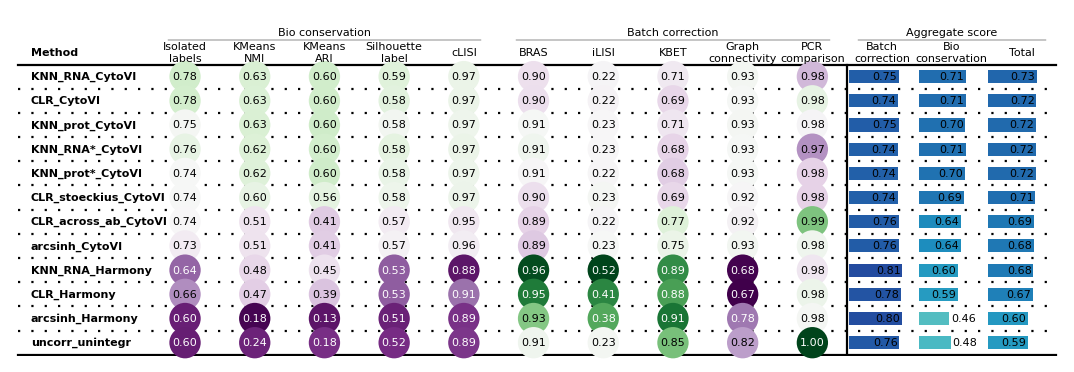

In [79]:
bm.plot_results_table(show=False, width=1.9, save_dir=save_directory, figsize=(8.35, 2.8))

# Supplementary Figure 4

In [80]:
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt

import utils  # From the utils.py file.

In [81]:
selected_dataset_and_methods = {'protein_uncorrected': "Uncorrected", "library_normalization": "Library normalization", "CLR_normalization": "CLR normalization", "KNN_protein_neighbors": "KNN normalization, protein", "KNN_RNA_neighbors": "KNN normalization, RNA"}
methods_palette = {"Uncorrected": "#FFB49A", "Library normalization": "#008080", "CLR normalization": "#7b7554", "KNN normalization, protein": "#51CB20", "KNN normalization, RNA": "#A11692", "CLR normalization Stoeckius": "#FFD166", "CLR normalization protein": "#1B5299"}
cell_types_palette = {'Treg':"#B5DEAD", 'other T':"#B5DEAD", 'CD4 T': "#F75C03", 'CD8 T': "#157F1F", 'NK': "#B2ABF2", 'B': "#6EA4BF", 'Plasma': "#1A181B", 'DC': "#CBC0AD", "cDC": "#FFD166", "pDC": "#EE7674" , 'Macro': "#15616D", 'Mono-Macro': "#D8DDEF", 'Mono': "#A833B9", "CD14 Mono": "#1B5299", "CD16 Mono": "#57A773", 'Mast': "#7B2D26", "Fibroblast": "#B4C5E4"}
sample_palette = {'p026t': "#353531", 'p042n': '#EC4E20', 'p042t': '#FF9505', 'P123_PBMC': '#016FB9', 'P123_Tissue': '#000000', 'P125_PBMC': '#FFADC6', 'P125_Tissue': '#DFE2CF', 'P126_PBMC': '#20BF55', 'P126_Tissue': '#01BAEF', 'P127_PBMC': '#FBFBFF', 'P127_Tissue': '#FFC759', 'P131_PBMC': '#44CFCB', 'P131_Tissue': '#9FC2CC'}

In [82]:
rcparams = {'font.size': 7,
    'axes.titlesize': 7,
    'axes.labelsize': 7,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'legend.fontsize': 7,
    'figure.titlesize': 7,
    'text.usetex': False,
    'font.family': 'sans-serif',
    'font.sans-serif': ['DejaVu Sans'],
    'mathtext.fontset': 'dejavusans', 
    'mathtext.rm': 'DejaVu Sans',
    'mathtext.it': 'DejaVu Sans:italic',
    'mathtext.bf': 'DejaVu Sans:bold',
           }

In [83]:
rna = sc.read_h5ad("Immune_colon_rna_data.h5ad")
protein = sc.read_h5ad("Immune_colon_protein_data.h5ad")

In [84]:
# Supplementary Figures 4A-B
def best_neighbors(filename="supp_fig_4B_SNR_n_neighbors.csv", 
                   metric="SNR", metric_name_in_file="average", sample_column_name="sample", sample_word_number=1,
                   figsize=(3.5, 3),
                   ):
    '''Analysis of the number of neighbors.'''

    snr_scores = pd.read_csv(filename, index_col="Unnamed: 0")
    snr_scores = snr_scores.dropna(axis=1)
    snr_scores = snr_scores.iloc[1:, :]
    idx_to_remove = []
    for idx in snr_scores.index:
        if idx.split("_")[-1] == "neighbors":
                idx_to_remove.append(idx)
    snr_scores = snr_scores[~snr_scores.index.isin(idx_to_remove)]

    snr_scores_n_neighbor_test = snr_scores
    snr_scores_n_neighbor_test[sample_column_name] = ["_".join(norm.split("_")[:sample_word_number]) for norm in snr_scores_n_neighbor_test.index]
    from collections import Counter
    n_cells = Counter(protein.obs[sample_column_name])
    snr_scores_n_neighbor_test["n_cells"] = [n_cells[sample] for sample in snr_scores_n_neighbor_test[sample_column_name]]
    snr_scores_n_neighbor_test_simplified = snr_scores_n_neighbor_test[["n_cells", metric_name_in_file, sample_column_name]]
    snr_scores_n_neighbor_test_simplified.to_csv(f"figures/n_neighbor_analysis_{metric}.csv", index=True)

    # Calculate the best number of neighbors.
    best_n_neighbors = snr_scores_n_neighbor_test.loc[snr_scores_n_neighbor_test.groupby(sample_column_name)[metric_name_in_file].idxmax()]
    best_n_neighbors["best_n_neighbors"] = [index.split("_")[-1].replace("n", "") for index in best_n_neighbors.index]
    best_n_neighbors = best_n_neighbors[["n_cells", "best_n_neighbors"]]
    best_n_neighbors = best_n_neighbors.astype(int)
    best_n_neighbors.to_csv(f"figures/figures_n_neighbors_best_{metric}.csv", index=True)

    # Perform linear regression to calculate the best number of neighbors based on the number of cells in the data.
    from sklearn.linear_model import LinearRegression

    df = best_n_neighbors

    # Reshape data for sklearn
    X = df["n_cells"].values.reshape(-1, 1)  # Independent variable (reshaped to 2D)
    y = df["best_n_neighbors"].values        # Dependent variable

    # Perform linear regression
    model = LinearRegression()
    model.fit(X, y)

    # Get regression coefficients
    slope = model.coef_[0]  # m
    intercept = model.intercept_  # b

    # Generate predictions for the regression line
    y_pred = model.predict(X)

    with plt.rc_context(rcparams):
        fig, ax = plt.subplots(figsize=figsize)

        # Plot the data points
        ax.scatter(df["n_cells"], df["best_n_neighbors"], color='blue', label="Data points")

        # Plot the regression line
        ax.plot(df["n_cells"], y_pred, color='red', label="Regression line")

        # Leave headroom so the equation box does not cover data points
        ax.margins(y=0.15)

        # Display the regression equation in axes coordinates (top left corner)
        equation_text = f"y = {slope:.4f}x + {intercept:.4f}"
        ax.text(0.03, 0.97, equation_text, transform=ax.transAxes,
                ha="left", va="top", color="black",
                bbox=dict(facecolor="white", alpha=0.5))

        # Labels
        ax.set_xlabel("Number of cells in the sample")
        ax.set_ylabel(f"Best number of neighbors by {metric}")

        # Legend inside the plot, placed where it overlaps the fewest data points
        ax.legend(loc="best")

        fig.tight_layout()
        fig.savefig(f"figures/supp_fig_4_n_neighbors_best_regression_{metric}.pdf")
        plt.show()

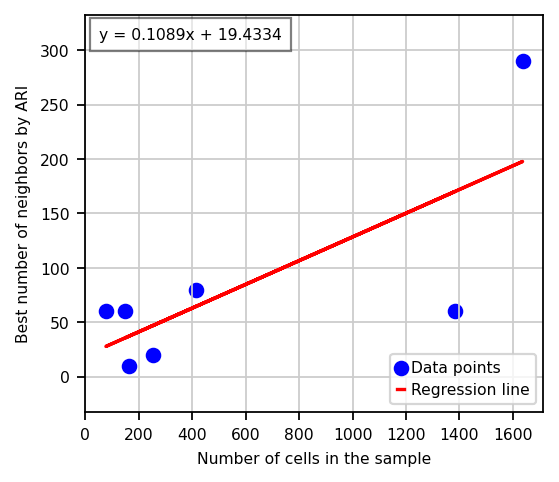

In [85]:
# Supplementary Figure 4A
best_neighbors(filename="supp_fig_4A_ARI_n_neighbors.csv",
               metric="ARI", metric_name_in_file="ARI",
               )

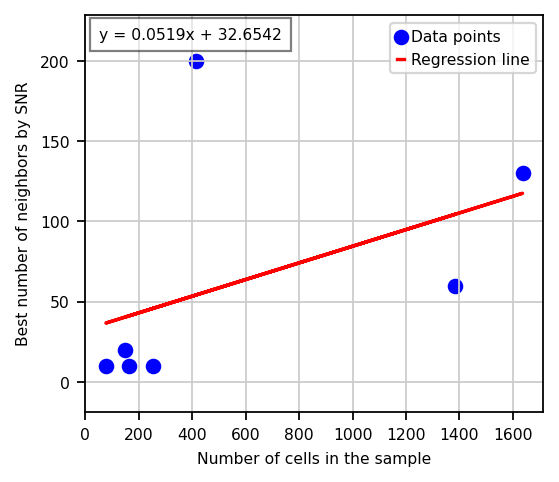

In [86]:
# Supplementary Figure 4B
best_neighbors()

In [87]:
# Supplementary Figure 4C.
ari_df = pd.read_csv(f"supp_fig_4C_ARI_pseudocounts.csv", index_col=0)
utils.boxplot_comparing_normalizations(ari_df, savefilename=f"figures/supp_fig_4C_ARI_by_pseudocount_value", profi=False, metric="ARI", selected_dataset_and_methods=selected_dataset_and_methods, sample_word_number=sample_word_number, methods_palette=methods_palette, figsize=(2.12, 1.60), rcparams=rcparams, orientation="vertical")


In [88]:
# Supplementary Figure 4D.
snr_scores = pd.read_csv(f"supp_fig_4D_SNR_pseudocounts.csv", index_col=0)
utils.boxplot_comparing_normalizations(snr_scores, savefilename=f"figures/supp_fig_4D_SNR_by_pseudocount_value", profi=False, metric="SNR", selected_dataset_and_methods=selected_dataset_and_methods, sample_word_number=sample_word_number, methods_palette=methods_palette, orientation="vertical")